# Light Deflection versus Black-Hole Spin

The deflection angle (finite-distance definition of the main articles, see `Lambda_Deflection.ipynb`) is computed for
every combination of spin $a$ (prograde $a > 0$ and retrograde $a < 0$) and cosmological constant $\Lambda$; for each
$\Lambda$ the results are fitted with the model $\delta(a) = A\,e^{-B a} + C$, separately for prograde and retrograde
spins. All data are taken directly from the simulation. See `docs/METHODOLOGY.md` for the full methodology.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kerr_ds import analytic, run_spin_sweep, fit_curve, exponential_decay, plot_spin_fit

## Parameters

In [2]:
# Physical parameters
M = 1.0
spins = [-0.99, -0.8, -0.6, -0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 0.99]
lambdas = [0.0, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6]  # negative values may be added as well

# Initial position of the photon
r0 = 500.0
theta0 = np.pi / 2
phi0 = 0.0

# Photon energy and impact parameter (L = b E)
E = 1.0
b = 7
L_ang = b * E

# Integration parameters
dtau = 0.05
max_steps = 30000

## Simulation

All combinations (11 spins × 7 values of $\Lambda$ = 77 trajectories) run in parallel in a single process pool
(about 5 minutes on a 4-core CPU). The horizon radius used for the capture condition is computed per spin.

In [3]:
results = run_spin_sweep(M, spins, lambdas, r0, theta0, phi0, E, L_ang,
                         dtau=dtau, max_steps=max_steps)

a          | Lambda     | Deflection (deg)   | dphi - pi (deg)    | Status
-------------------------------------------------------------------------------


-0.99      | 0.0        | 246.062496         | 244.470259         | Steps: 20374


-0.99      | 1e-08      | 246.062951         | 244.471579         | Steps: 20374


-0.99      | 5e-08      | 246.064766         | 244.476855         | Steps: 20374


-0.99      | 1e-07      | 246.067023         | 244.483450         | Steps: 20374


...

0.99       | 5e-08      | 45.507596          | 43.915907          | Steps: 20140


0.99       | 1e-07      | 45.506203          | 43.916931          | Steps: 20140


0.99       | 5e-07      | 45.495051          | 43.925228          | Steps: 20140


0.99       | 1e-06      | 45.481094          | 43.935865          | Steps: 20140


0.99       | 5e-06      | 45.372598          | 44.035493          | Steps: 20140


## Deflection table (degrees)

In [4]:
# deflections[Lambda] = deflection angle for each spin (in the order of `spins`)
deflections = {lmd: np.array([results[a, lmd].deflection_deg for a in spins]) for lmd in lambdas}

print(f"{'Lambda':<10}" + "".join(f"{f'a = {a}':>11}" for a in spins))
for lmd, y in deflections.items():
    print(f"{lmd:<10}" + "".join(f"{v:>11.4f}" for v in y))

# Check against the exact deflection angle (quadrature) at the same source and observer radii
diff = max(abs(res.deflection_deg - analytic.deflection_exact_deg(M, a, lmd, b, r0, res.r[-1]))
           for (a, lmd), res in results.items())
print(f"\nmax |simulation - exact| over all {len(results)} trajectories = {diff:.2e} deg")

Lambda      a = -0.99   a = -0.8   a = -0.6   a = -0.4   a = -0.2    a = 0.0    a = 0.2    a = 0.4    a = 0.6    a = 0.8   a = 0.99
0.0          246.0625   120.7932    94.9708    80.9228    71.5281    64.6058    59.2038    54.8240    51.1740    48.0686    45.5090
1e-08        246.0630   120.7923    94.9699    80.9219    71.5274    64.6051    59.2033    54.8235    51.1736    48.0682    45.5087
5e-08        246.0648   120.7886    94.9664    80.9187    71.5244    64.6025    59.2009    54.8214    51.1718    48.0668    45.5076
1e-07        246.0670   120.7840    94.9620    80.9146    71.5207    64.5992    59.1980    54.8189    51.1697    48.0650    45.5062
5e-07        246.0846   120.7466    94.9263    80.8818    71.4908    64.5724    59.1743    54.7984    51.1523    48.0509    45.4951
1e-06        246.1054   120.6986    94.8807    80.8397    71.4527    64.5382    59.1442    54.7723    51.1304    48.0330    45.4811
5e-06        246.2022   120.2479    94.4567    80.4522    71.1040    64.2293


max |simulation - exact| over all 77 trajectories = 5.49e-07 deg


## Exponential fits

For each $\Lambda$: $\delta(a) = A\,e^{-B a} + C$ (`scipy.optimize.curve_fit`), with
$R^2 = 1 - SS_\text{res}/SS_\text{tot}$, fitted separately for prograde ($a \ge 0$) and retrograde ($a \le 0$) spins.
The model is descriptive only. For retrograde photons the critical impact parameter $b_c$ approaches $7M$ as
$a \to -M$ (Congdon et al. 2022), so for $b = 7$ the deflection angle diverges logarithmically there
(Bozza 2002); the fitted curves must not be extrapolated to $a = -1$.

In [5]:
groups = {"prograde": [a for a in spins if a >= 0], "retrograde": [a for a in spins if a <= 0]}
p0s = {"prograde": [300, 5, 70], "retrograde": [1, 6, 70]}
fits = {}
for name, group in groups.items():
    idx = [spins.index(a) for a in group]
    fits[name] = {}
    print(f"--- {name} ---")
    for lmd, y in deflections.items():
        fits[name][lmd] = fit_curve(exponential_decay, group, y[idx], p0=p0s[name], maxfev=20000)
        (A, B, C), r2 = fits[name][lmd]
        print(f"Λ = {lmd:<8g}: y = {A:.4f} * e^(-{B:.4f} * a) + {C:.4f}   (R² = {r2:.6f})")

print("\nCritical impact parameter b_c (Lambda = 0) for the retrograde spins:")
for a in groups["retrograde"]:
    print(f"  a = {a:<6}: b_c = {analytic.critical_impact_parameter(M, a, 0.0)[0]:.4f}   (b = {b})")

--- prograde ---
Λ = 0       : y = 32.3813 * e^(-0.8940 * a) + 32.1902   (R² = 0.999955)
Λ = 1e-08   : y = 32.3802 * e^(-0.8941 * a) + 32.1906   (R² = 0.999955)
Λ = 5e-08   : y = 32.3759 * e^(-0.8941 * a) + 32.1923   (R² = 0.999955)
Λ = 1e-07   : y = 32.3705 * e^(-0.8942 * a) + 32.1943   (R² = 0.999955)
Λ = 5e-07   : y = 32.3268 * e^(-0.8950 * a) + 32.2113   (R² = 0.999955)
Λ = 1e-06   : y = 32.2704 * e^(-0.8960 * a) + 32.2336   (R² = 0.999955)
Λ = 5e-06   : y = 31.7146 * e^(-0.9059 * a) + 32.4811   (R² = 0.999956)
--- retrograde ---
Λ = 0       : y = 0.4437 * e^(-6.0327 * a) + 70.9952   (R² = 0.993144)
Λ = 1e-08   : y = 0.4437 * e^(-6.0328 * a) + 70.9946   (R² = 0.993144)
Λ = 5e-08   : y = 0.4436 * e^(-6.0330 * a) + 70.9921   (R² = 0.993144)
Λ = 1e-07   : y = 0.4434 * e^(-6.0334 * a) + 70.9890   (R² = 0.993145)
Λ = 5e-07   : y = 0.4424 * e^(-6.0361 * a) + 70.9639   (R² = 0.993148)
Λ = 1e-06   : y = 0.4410 * e^(-6.0395 * a) + 70.9318   (R² = 0.993152)
Λ = 5e-06   : y = 0.4293 * e^(-6.0

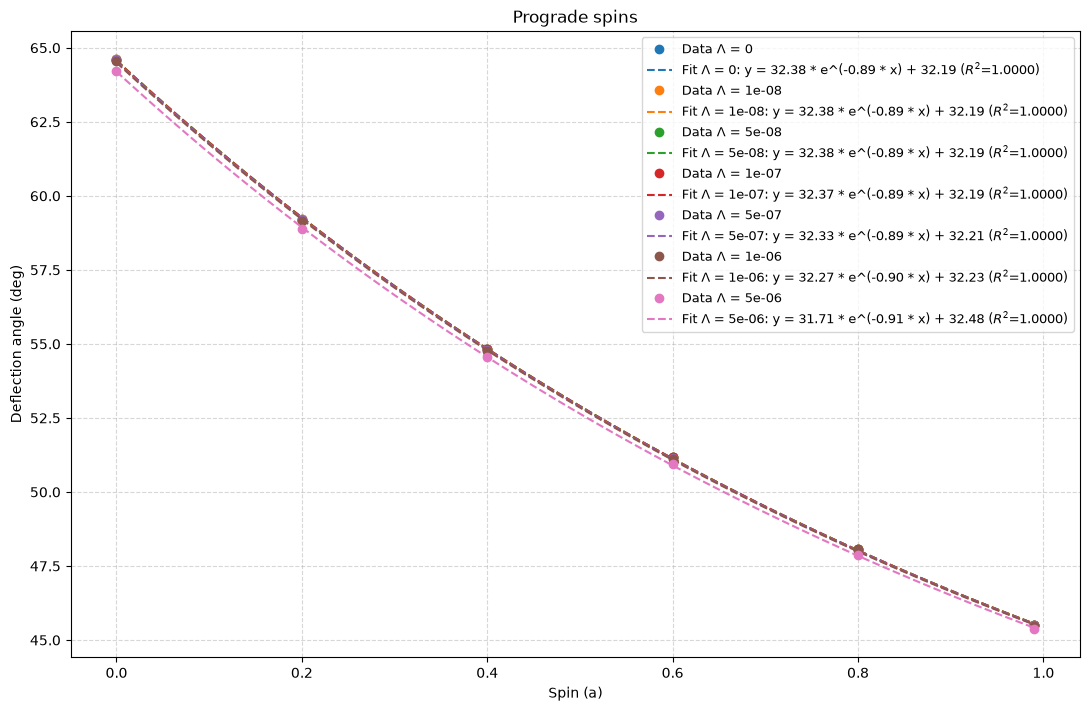

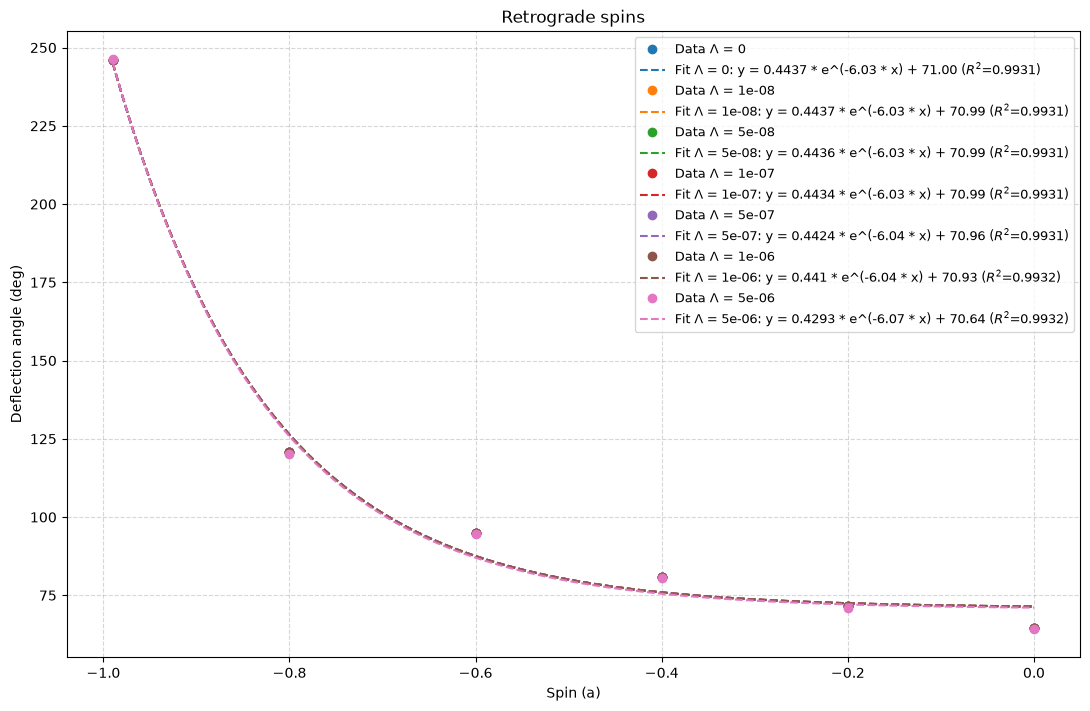

In [6]:
for name, group in groups.items():
    idx = [spins.index(a) for a in group]
    plot_spin_fit(group, {lmd: y[idx] for lmd, y in deflections.items()}, fits[name])
    plt.title(f"{name.capitalize()} spins")
    plt.show()